# Retail Sales Analysis with PySpark

A small learning project: processing ~1M rows of real online-retail transactions with PySpark.

**Dataset:** [Online Retail II (UCI)](https://archive.ics.uci.edu/dataset/502/online+retail+ii): transactions of a UK-based online retailer, Dec 2009 – Dec 2011.

**What this notebook covers:**
1. Creating a SparkSession and reading data with an explicit schema
2. Cleaning: nulls, cancellations, invalid quantities/prices, duplicates
3. Aggregations with `groupBy`
4. Weekly demand per product with **window functions** (moving average, lag, week-over-week change)
5. The same kind of analysis in **Spark SQL**
6. Writing results to **Parquet**

## 0. Setup

Requirements: Python 3.10+, Java 17 or 21, and `pip install pyspark pandas openpyxl`.

Download `online_retail_II.xlsx` from the UCI link above and put it in a `data/` folder next to this notebook.

In [2]:
from pyspark.sql import SparkSession, functions as F
from pyspark.sql.window import Window
from pyspark.sql.types import StructType, StructField, StringType, IntegerType, DoubleType

spark = (
    SparkSession.builder
    .appName("RetailSalesPySpark")
    .master("local[*]")                          # use all local CPU cores
    .config("spark.sql.session.timeZone", "UTC")
    .config("spark.sql.shuffle.partitions", "8")  # default is 200; too many for a small local dataset
    .config("spark.ui.showConsoleProgress", "false")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("WARN")
spark.version

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/01 17:57:35 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


'4.2.0'

## 1. Convert Excel to CSV (one-time)

Spark cannot read `.xlsx` natively, so we convert it once with pandas. The file has two sheets (2009–2010 and 2010–2011); we combine them.
This step can take a few minutes. It is skipped if the CSV already exists.

In [3]:
import os
import pandas as pd

XLSX_PATH = "data/online_retail_II.xlsx"
CSV_PATH = "data/online_retail_II.csv"

if not os.path.exists(CSV_PATH):
    sheets = pd.read_excel(
        XLSX_PATH, sheet_name=None,
        dtype={"Invoice": str, "StockCode": str, "Customer ID": str},
    )
    pd.concat(sheets.values(), ignore_index=True).to_csv(CSV_PATH, index=False)
    print("CSV written:", CSV_PATH)
else:
    print("CSV already exists, skipping conversion")

CSV written: data/online_retail_II.csv


## 2. Read with an explicit schema

Defining the schema ourselves is faster than `inferSchema=True` (Spark doesn't need an extra pass over the data) and avoids wrong type guesses.
`InvoiceDate` is read as a string first and parsed afterwards, so the notebook works with both the pandas-converted CSV and common CSV versions found online.

In [4]:
schema = StructType([
    StructField("Invoice", StringType()),
    StructField("StockCode", StringType()),
    StructField("Description", StringType()),
    StructField("Quantity", IntegerType()),
    StructField("InvoiceDate", StringType()),
    StructField("Price", DoubleType()),
    StructField("Customer ID", StringType()),
    StructField("Country", StringType()),
])

raw = (
    spark.read.csv(CSV_PATH, header=True, schema=schema)
    .withColumnRenamed("Customer ID", "CustomerID")
    .withColumn(
        "InvoiceDate",
        F.coalesce(
            F.try_to_timestamp("InvoiceDate", F.lit("yyyy-MM-dd HH:mm:ss")),
            F.try_to_timestamp("InvoiceDate", F.lit("M/d/yyyy H:mm")),
        ),
    )
)

raw.printSchema()
raw.show(5, truncate=False)
print("Raw rows:", raw.count())

root
 |-- Invoice: string (nullable = true)
 |-- StockCode: string (nullable = true)
 |-- Description: string (nullable = true)
 |-- Quantity: integer (nullable = true)
 |-- InvoiceDate: timestamp (nullable = true)
 |-- Price: double (nullable = true)
 |-- CustomerID: string (nullable = true)
 |-- Country: string (nullable = true)

+-------+---------+-----------------------------------+--------+-------------------+-----+----------+--------------+
|Invoice|StockCode|Description                        |Quantity|InvoiceDate        |Price|CustomerID|Country       |
+-------+---------+-----------------------------------+--------+-------------------+-----+----------+--------------+
|489434 |85048    |15CM CHRISTMAS GLASS BALL 20 LIGHTS|12      |2009-12-01 07:45:00|6.95 |13085     |United Kingdom|
|489434 |79323P   |PINK CHERRY LIGHTS                 |12      |2009-12-01 07:45:00|6.75 |13085     |United Kingdom|
|489434 |79323W   | WHITE CHERRY LIGHTS               |12      |2009-12-01 07:45:

## 3. Cleaning

Rules:
- Drop rows without a customer ID
- Drop cancellations (invoice numbers starting with `C`)
- Keep only positive quantities and prices
- Drop exact duplicate rows
- Add a `Revenue` column

Spark is **lazy**: these transformations only build a plan; nothing runs until an action like `count()` or `show()`. We `cache()` the clean data because we reuse it many times below.

In [6]:
clean = (
    raw
    .filter(F.col("CustomerID").isNotNull())
    .filter(F.col("InvoiceDate").isNotNull())
    .filter(~F.col("Invoice").startswith("C"))
    .filter((F.col("Quantity") > 0) & (F.col("Price") > 0))
    .dropDuplicates()
    .withColumn("Revenue", F.round(F.col("Quantity") * F.col("Price"), 2))
    .cache()
)

n_raw, n_clean = raw.count(), clean.count()
print(f"Raw: {n_raw:,} | Clean: {n_clean:,} | Removed: {n_raw - n_clean:,} ({(n_raw - n_clean) / n_raw:.1%})")

26/10/01 18:01:36 WARN CacheManager: Asked to cache already cached data.


Raw: 1,067,371 | Clean: 779,425 | Removed: 287,946 (27.0%)


## 4. Aggregations with `groupBy`

In [7]:
# Top 10 products by revenue
top_products = (
    clean.groupBy("StockCode")
    .agg(
        F.first("Description", ignorenulls=True).alias("Description"),
        F.sum("Quantity").alias("TotalQuantity"),
        F.round(F.sum("Revenue"), 2).alias("TotalRevenue"),
        F.countDistinct("Invoice").alias("NumOrders"),
    )
    .orderBy(F.desc("TotalRevenue"))
)
top_products.show(10, truncate=False)

+---------+----------------------------------+-------------+------------+---------+
|StockCode|Description                       |TotalQuantity|TotalRevenue|NumOrders|
+---------+----------------------------------+-------------+------------+---------+
|22423    |REGENCY CAKESTAND 3 TIER          |24124        |277656.25   |3317     |
|85123A   |WHITE HANGING HEART T-LIGHT HOLDER|91814        |247203.36   |4895     |
|23843    |PAPER CRAFT , LITTLE BIRDIE       |80995        |168469.6    |1        |
|85099B   |JUMBO BAG RED WHITE SPOTTY        |93436        |167920.64   |3260     |
|M        |Manual                            |9384         |151777.67   |620      |
|POST     |POSTAGE                           |5235         |124648.04   |1803     |
|84879    |ASSORTED COLOUR BIRD ORNAMENT     |78234        |124351.86   |2652     |
|47566    |PARTY BUNTING                     |23460        |103283.38   |2077     |
|23166    |MEDIUM CERAMIC TOP STORAGE JAR    |77916        |81416.73    |195

In [8]:
# Revenue by country, with each country's share of total revenue
total_revenue = clean.agg(F.sum("Revenue")).first()[0]

by_country = (
    clean.groupBy("Country")
    .agg(
        F.round(F.sum("Revenue"), 2).alias("Revenue"),
        F.countDistinct("CustomerID").alias("Customers"),
    )
    .withColumn("RevenueShare", F.round(F.col("Revenue") / total_revenue, 4))
    .orderBy(F.desc("Revenue"))
)
by_country.show(10, truncate=False)

+--------------+------------+---------+------------+
|Country       |Revenue     |Customers|RevenueShare|
+--------------+------------+---------+------------+
|United Kingdom|1.43892349E7|5350     |0.8282      |
|EIRE          |616570.54   |5        |0.0355      |
|Netherlands   |554038.09   |22       |0.0319      |
|Germany       |425019.71   |107      |0.0245      |
|France        |348768.96   |95       |0.0201      |
|Australia     |169283.46   |15       |0.0097      |
|Spain         |108332.49   |41       |0.0062      |
|Switzerland   |100061.94   |22       |0.0058      |
|Sweden        |91515.82    |19       |0.0053      |
|Denmark       |68580.69    |12       |0.0039      |
+--------------+------------+---------+------------+
only showing top 10 rows


## 5. Weekly demand per product with window functions

First we aggregate sales to **product × week**. Then, with a window partitioned by product and ordered by week, we compute:
- `MA4`: 4-week moving average of quantity (current week + previous 3)
- `PrevWeekQty`: last week's quantity (`lag`)
- `WoWChange`: week-over-week % change

**Limitation:** weeks in which a product sold nothing do not appear as rows, so `lag` and the moving average skip them. For real demand forecasting you would fill missing weeks with 0 first.

In [9]:
weekly = (
    clean
    .withColumn("Week", F.date_trunc("week", "InvoiceDate").cast("date"))
    .groupBy("StockCode", "Week")
    .agg(
        F.sum("Quantity").alias("WeeklyQty"),
        F.round(F.sum("Revenue"), 2).alias("WeeklyRevenue"),
    )
)

w = Window.partitionBy("StockCode").orderBy("Week")

weekly_features = (
    weekly
    .withColumn("MA4", F.round(F.avg("WeeklyQty").over(w.rowsBetween(-3, 0)), 2))
    .withColumn("PrevWeekQty", F.lag("WeeklyQty", 1).over(w))
    .withColumn(
        "WoWChange",
        F.round((F.col("WeeklyQty") - F.col("PrevWeekQty")) / F.col("PrevWeekQty"), 3),
    )
)

# Look at the best-selling product
best = top_products.first()["StockCode"]
weekly_features.filter(F.col("StockCode") == best).orderBy("Week").show(12)

+---------+----------+---------+-------------+------+-----------+---------+
|StockCode|      Week|WeeklyQty|WeeklyRevenue|   MA4|PrevWeekQty|WoWChange|
+---------+----------+---------+-------------+------+-----------+---------+
|    22423|2010-03-15|      192|       2332.8| 192.0|       NULL|     NULL|
|    22423|2010-03-22|      410|       4673.1| 301.0|        192|    1.135|
|    22423|2010-03-29|      137|      1645.95|246.33|        410|   -0.666|
|    22423|2010-04-05|      216|       2480.4|238.75|        137|    0.577|
|    22423|2010-04-12|      295|      3444.45| 264.5|        216|    0.366|
|    22423|2010-04-19|      331|      3831.45|244.75|        295|    0.122|
|    22423|2010-04-26|      259|      3043.05|275.25|        331|   -0.218|
|    22423|2010-05-03|      300|       3450.6|296.25|        259|    0.158|
|    22423|2010-05-10|      126|       1520.1| 254.0|        300|    -0.58|
|    22423|2010-05-17|       24|        306.0|177.25|        126|    -0.81|
|    22423|2

+----------+---------+
|      Week|  Revenue|
+----------+---------+
|2009-11-30|232177.51|
|2009-12-07|207908.73|
|2009-12-14|207685.87|
|2009-12-21|  35731.9|
|2010-01-04|167636.95|
|2010-01-11|125493.61|
|2010-01-18|119473.35|
|2010-01-25|143198.76|
|2010-02-01|112299.69|
|2010-02-08| 80059.66|
+----------+---------+
only showing top 10 rows


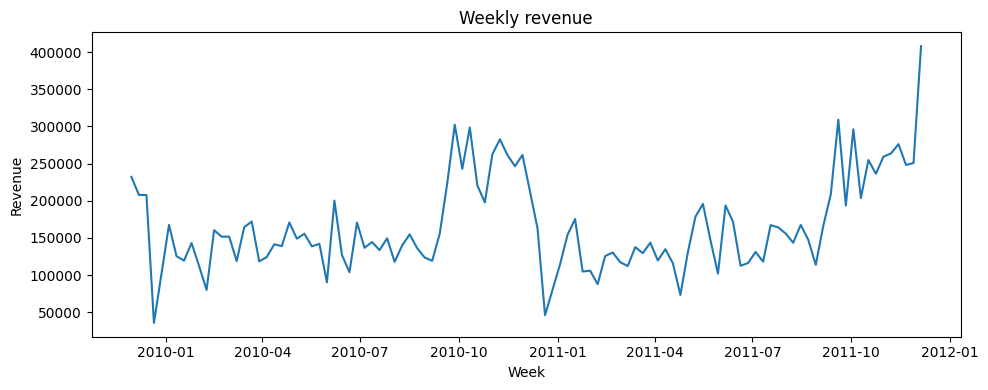

In [13]:
# Company-wide weekly revenue trend
weekly_total = (
    weekly.groupBy("Week")
    .agg(F.round(F.sum("WeeklyRevenue"), 2).alias("Revenue"))
    .orderBy("Week")
)
weekly_total.show(10)

# Optional: plot it (small result, so converting to pandas is fine)
import matplotlib.pyplot as plt
pdf = weekly_total.toPandas()
plt.figure(figsize=(10, 4))
plt.plot(pdf["Week"], pdf["Revenue"])
plt.title("Weekly revenue")
plt.xlabel("Week")
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()


## 6. Spark SQL

The same DataFrame can be queried with SQL by registering it as a temporary view. Here: monthly revenue for the top 5 countries.

In [14]:
clean.createOrReplaceTempView("sales")

monthly_top_countries = spark.sql("""
    WITH top_countries AS (
        SELECT Country
        FROM sales
        GROUP BY Country
        ORDER BY SUM(Revenue) DESC
        LIMIT 5
    )
    SELECT
        s.Country,
        DATE_TRUNC('month', s.InvoiceDate) AS Month,
        ROUND(SUM(s.Revenue), 2)           AS Revenue
    FROM sales s
    JOIN top_countries t ON s.Country = t.Country
    GROUP BY s.Country, DATE_TRUNC('month', s.InvoiceDate)
    ORDER BY s.Country, Month
""")
monthly_top_countries.show(10, truncate=False)

+-------+-------------------+--------+
|Country|Month              |Revenue |
+-------+-------------------+--------+
|EIRE   |2009-12-01 00:00:00|18170.46|
|EIRE   |2010-01-01 00:00:00|65031.41|
|EIRE   |2010-02-01 00:00:00|20206.46|
|EIRE   |2010-03-01 00:00:00|22989.46|
|EIRE   |2010-04-01 00:00:00|20668.08|
|EIRE   |2010-05-01 00:00:00|18430.91|
|EIRE   |2010-06-01 00:00:00|22934.34|
|EIRE   |2010-07-01 00:00:00|31987.23|
|EIRE   |2010-08-01 00:00:00|22919.36|
|EIRE   |2010-09-01 00:00:00|36322.78|
+-------+-------------------+--------+
only showing top 10 rows


## 7. Save results as Parquet

Parquet is a columnar format: smaller than CSV, keeps the schema, and is fast to read back in Spark.

In [15]:
weekly_features.write.mode("overwrite").parquet("output/weekly_product_features")
by_country.write.mode("overwrite").parquet("output/revenue_by_country")

# Read back to check
spark.read.parquet("output/weekly_product_features").show(5)

+---------+----------+---------+-------------+-----+-----------+---------+
|StockCode|      Week|WeeklyQty|WeeklyRevenue|  MA4|PrevWeekQty|WoWChange|
+---------+----------+---------+-------------+-----+-----------+---------+
|    10109|2009-11-30|        4|         1.68|  4.0|       NULL|     NULL|
|    10120|2009-11-30|      100|         21.0|100.0|       NULL|     NULL|
|    10120|2009-12-07|        4|         0.84| 52.0|        100|    -0.96|
|    10120|2009-12-14|        2|         0.42|35.33|          4|     -0.5|
|    10120|2010-01-04|       30|          6.3| 34.0|          2|     14.0|
+---------+----------+---------+-------------+-----+-----------+---------+
only showing top 5 rows


In [ ]:
spark.stop()